# Complete three-state figure at $K=40$ and $T=50$

This notebook generates the three trajectory panels, the three terminal-distribution panels, and the complete six-panel figure. Panels (a) and (b) use seed 80; panel (c) uses seed 62.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde

repo_root = Path.cwd().resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
if not (repo_root / 'src').exists():
    raise RuntimeError('Open this notebook from the repository root or notebooks folder.')
sys.path.insert(0, str(repo_root))

from src.monte_carlo import MonteCarloParameters, simulate_trajectory
from src.initial_condition_states import simulate_asymmetric_bimodal

figure_dir = repo_root / 'figures'
figure_dir.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
    'axes.linewidth': 0.9,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

## 1. Parameters

In [2]:
common = dict(
    n=800, k=40, t_max=50, f_s=0.50,
    sigma_s=0.80, sigma_ns=0.10, gamma=4.0, d_c=0.50,
    x0_stubborn_positive=1.0, x0_stubborn_negative=-1.0,
    trajectory_seed=123, trajectories_per_bias_group=200,
)

bp_parameters = MonteCarloParameters(
    **common, seed=80,
    x0_nonstubborn_negative=-0.5, x0_nonstubborn_positive=0.5,
)
bu_parameters = MonteCarloParameters(
    **common, seed=80,
    x0_nonstubborn_negative=0.5, x0_nonstubborn_positive=0.5,
)
ab_parameters = MonteCarloParameters(
    **common, seed=62,
    x0_nonstubborn_negative=-0.5, x0_nonstubborn_positive=0.5,
)

cases = [
    {'panel': '(a)', 'key': 'bp', 'name': 'Bimodal polarized',
     'negative_mf': -0.7518939448845263, 'positive_mf': 0.7518939448845263,
     'distribution_color': '#6F4E9C'},
    {'panel': '(b)', 'key': 'bu', 'name': 'Biased unimodal',
     'negative_mf': 0.5514161221836354, 'positive_mf': 0.6679211791156909,
     'distribution_color': '#D9772B'},
    {'panel': '(c)', 'key': 'ab', 'name': 'Asymmetric bimodal polarized',
     'negative_mf': -0.7789415674149623, 'positive_mf': 0.6942938127229298,
     'distribution_color': '#6F4E9C'},
]
bp_parameters, bu_parameters, ab_parameters

(MonteCarloParameters(n=800, k=40, t_max=50, f_s=0.5, sigma_s=0.8, sigma_ns=0.1, gamma=4.0, d_c=0.5, x0_stubborn_positive=1.0, x0_stubborn_negative=-1.0, x0_nonstubborn_negative=-0.5, x0_nonstubborn_positive=0.5, seed=80, trajectory_seed=123, trajectories_per_bias_group=200),
 MonteCarloParameters(n=800, k=40, t_max=50, f_s=0.5, sigma_s=0.8, sigma_ns=0.1, gamma=4.0, d_c=0.5, x0_stubborn_positive=1.0, x0_stubborn_negative=-1.0, x0_nonstubborn_negative=0.5, x0_nonstubborn_positive=0.5, seed=80, trajectory_seed=123, trajectories_per_bias_group=200),
 MonteCarloParameters(n=800, k=40, t_max=50, f_s=0.5, sigma_s=0.8, sigma_ns=0.1, gamma=4.0, d_c=0.5, x0_stubborn_positive=1.0, x0_stubborn_negative=-1.0, x0_nonstubborn_negative=-0.5, x0_nonstubborn_positive=0.5, seed=62, trajectory_seed=123, trajectories_per_bias_group=200))

## 2. Run all three simulations

In [3]:
results = {
    'bp': simulate_trajectory(alpha2=0.03, parameters=bp_parameters),
    'bu': simulate_trajectory(alpha2=0.03, parameters=bu_parameters),
    'ab': simulate_asymmetric_bimodal(alpha2=0.03, parameters=ab_parameters),
}

for case in cases:
    result = results[case['key']]
    print(
        f"{case['name']}: N={result['parameters'].n}, "
        f"K={result['parameters'].k:g}, T={result['parameters'].t_max}, "
        f"seed={result['parameters'].seed}, B={result['B']:.3f}, S={result['S']:.3f}"
    )

Bimodal polarized: N=800, K=40, T=50, seed=80, B=0.936, S=0.003
Biased unimodal: N=800, K=40, T=50, seed=80, B=0.373, S=0.613
Asymmetric bimodal polarized: N=800, K=40, T=50, seed=62, B=0.946, S=0.399


## 3. Plotting functions

In [4]:
negative_mc_color = '#2166AC'
positive_mc_color = '#B2182B'
negative_mf_color = '#00A6D6'
positive_mf_color = '#EF3B6B'
negative_trace_color = '#92C5DE'
positive_trace_color = '#F4A6B6'

def style_axis(ax):
    ax.tick_params(direction='out', labelsize=12.5, width=0.9, length=4)
    ax.xaxis.label.set_size(18)
    ax.yaxis.label.set_size(18)

def draw_trajectory(ax, result, case):
    is_negative = result['sampled_is_negative']
    ax.plot(
        result['times'], result['sampled_history'][:, is_negative],
        color=negative_trace_color, alpha=0.28, linewidth=0.50, rasterized=True,
    )
    ax.plot(
        result['times'], result['sampled_history'][:, ~is_negative],
        color=positive_trace_color, alpha=0.28, linewidth=0.50, rasterized=True,
    )
    ax.plot(result['times'], result['negative_mean'], color=negative_mc_color, linewidth=2.2)
    ax.plot(result['times'], result['positive_mean'], color=positive_mc_color, linewidth=2.2)
    ax.axhline(case['negative_mf'], color=negative_mf_color, linewidth=1.9, linestyle='--')
    ax.axhline(case['positive_mf'], color=positive_mf_color, linewidth=1.9, linestyle='--')
    ax.set(xlim=(0, 50), ylim=(-1.02, 1.02), xlabel=r'$t$', ylabel=r'$x_i(t)$')
    ax.set_xticks([0, 10, 20, 30, 40, 50])
    ax.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])
    style_axis(ax)

def draw_distribution(ax, result, case):
    x_grid = np.linspace(-1.0, 1.0, 1000)
    density = gaussian_kde(result['final_opinions'])(x_grid)
    color = case['distribution_color']
    ax.fill_between(x_grid, 0.0, density, color=color, alpha=0.12, linewidth=0)
    ax.plot(x_grid, density, color=color, linewidth=2.2)
    ax.axvline(case['negative_mf'], color=negative_mf_color, linewidth=1.9, linestyle='--')
    ax.axvline(case['positive_mf'], color=positive_mf_color, linewidth=1.9, linestyle='--')
    ax.set(xlim=(-1.0, 1.0), ylim=(0, None), xlabel=r'$x_i$', ylabel=r'$p(x_i)$')
    ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
    style_axis(ax)

legend_handles = [
    Line2D([0], [0], color=negative_mc_color, lw=2.2, label='Negative MC mean'),
    Line2D([0], [0], color=positive_mc_color, lw=2.2, label='Positive MC mean'),
    Line2D([0], [0], color=negative_mf_color, lw=1.9, ls='--', label='Negative MF'),
    Line2D([0], [0], color=positive_mf_color, lw=1.9, ls='--', label='Positive MF'),
]

## 4. Generate the three trajectory panels

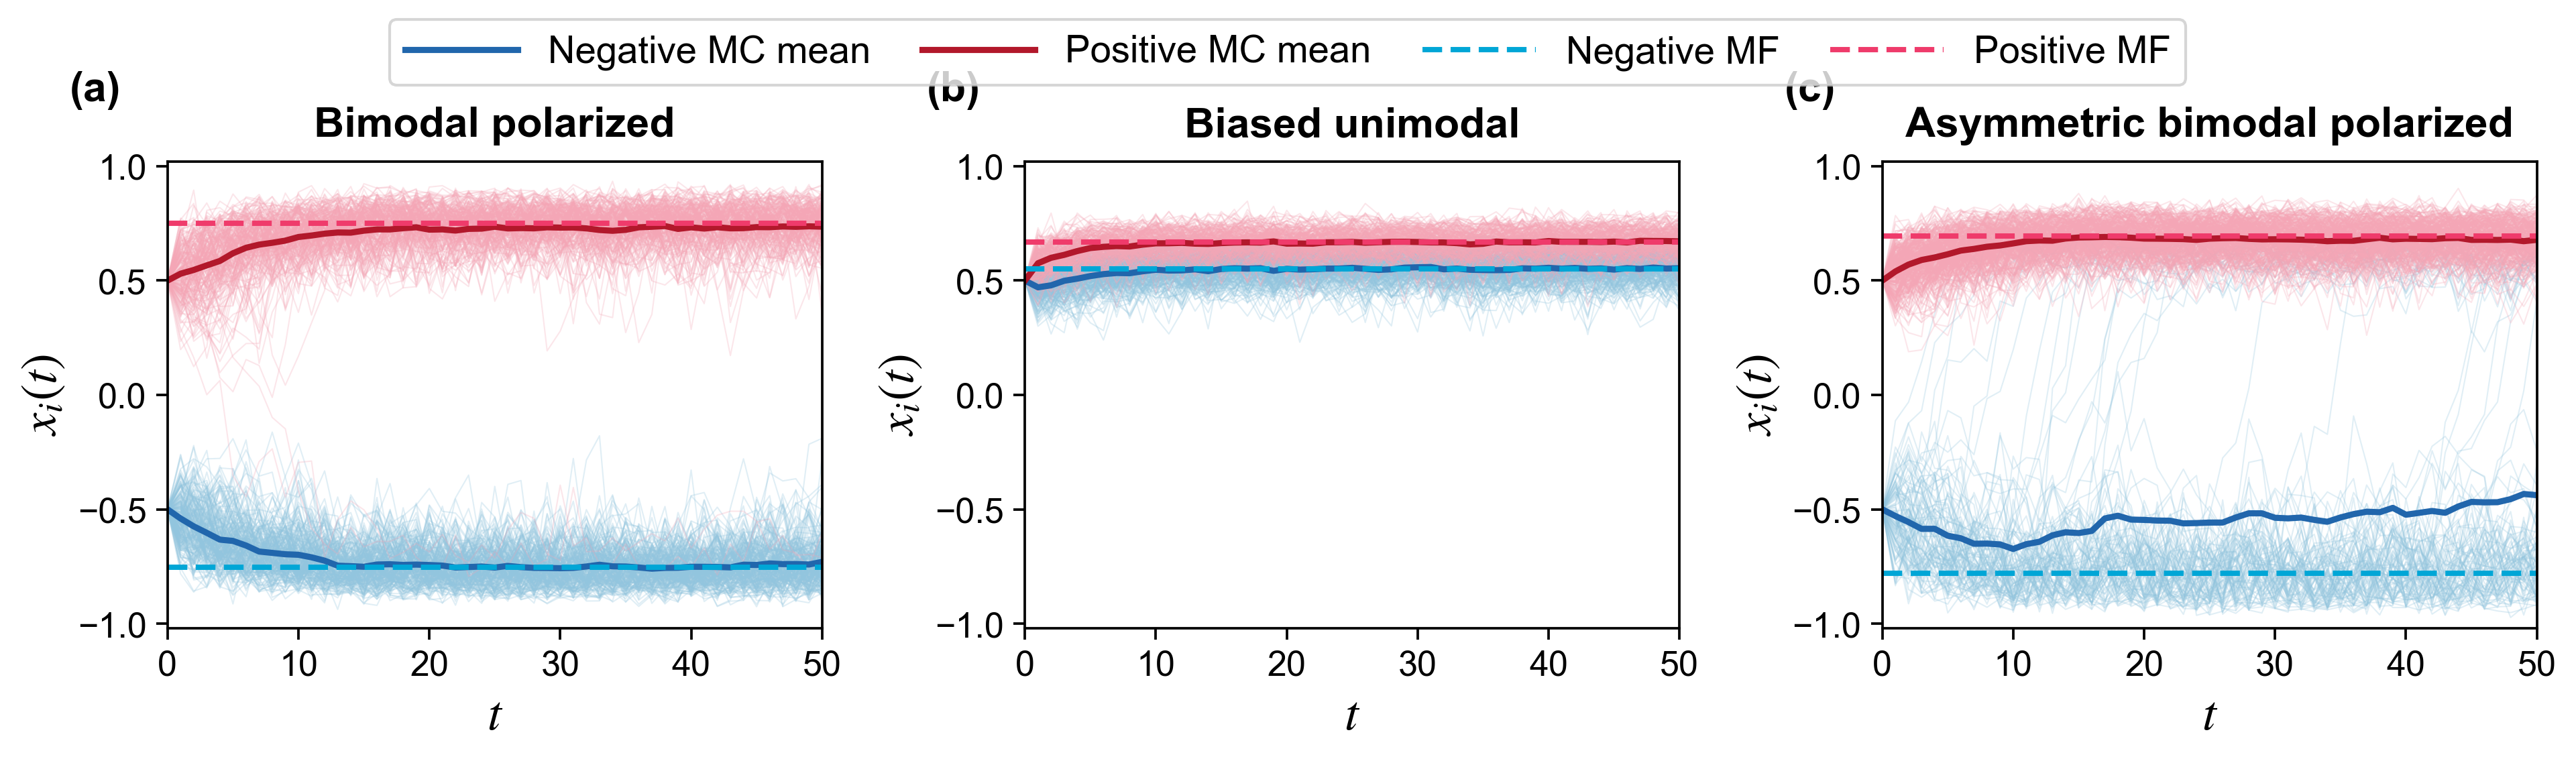

In [5]:
fig, axes = plt.subplots(
    1, 3, figsize=(12.8, 4.0), dpi=300,
    gridspec_kw={'left': 0.065, 'right': 0.985, 'bottom': 0.16, 'top': 0.74, 'wspace': 0.31},
)
for ax, case in zip(axes, cases):
    draw_trajectory(ax, results[case['key']], case)
    ax.set_title(case['name'], fontsize=15, fontweight='semibold', pad=9)
    ax.text(-0.15, 1.13, case['panel'], transform=ax.transAxes, fontsize=15, fontweight='bold')
fig.legend(
    handles=legend_handles, loc='upper center', ncol=4, frameon=True,
    bbox_to_anchor=(0.5, 0.94), fontsize=13.5, handlelength=3.0, columnspacing=1.35,
)
trajectory_base = figure_dir / 'three_states_K40_T50_seed62_trajectories'
fig.savefig(str(trajectory_base) + '.svg', bbox_inches='tight')
fig.savefig(str(trajectory_base) + '.pdf', bbox_inches='tight')
fig.savefig(str(trajectory_base) + '.png', dpi=600, bbox_inches='tight')
plt.show()

## 5. Generate the three terminal-distribution panels

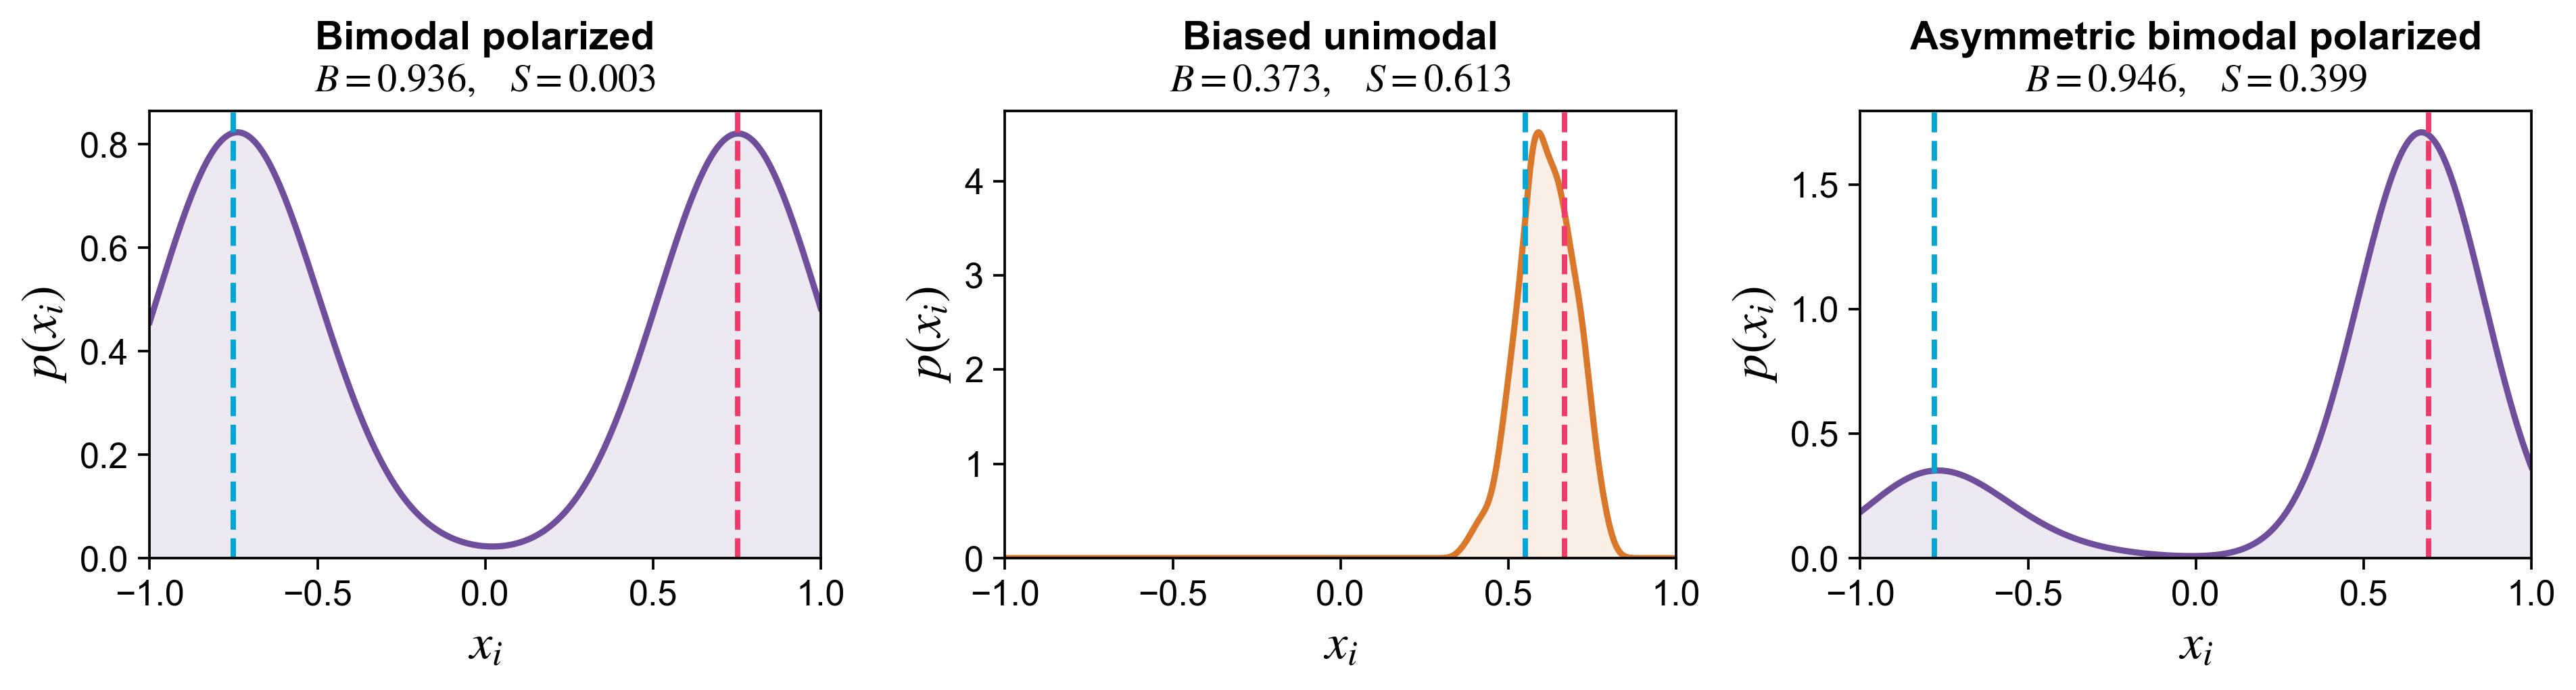

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.5), dpi=300)
for ax, case in zip(axes, cases):
    result = results[case['key']]
    draw_distribution(ax, result, case)
    ax.set_title(
        f"{case['name']}\n" + rf"$B={result['B']:.3f},\quad S={result['S']:.3f}$",
        fontsize=14, fontweight='semibold', pad=7,
    )
fig.tight_layout()
distribution_base = figure_dir / 'three_states_K40_T50_seed62_distributions'
fig.savefig(str(distribution_base) + '.svg', bbox_inches='tight')
fig.savefig(str(distribution_base) + '.pdf', bbox_inches='tight')
fig.savefig(str(distribution_base) + '.png', dpi=600, bbox_inches='tight')
plt.show()

## 6. Generate the complete six-panel figure

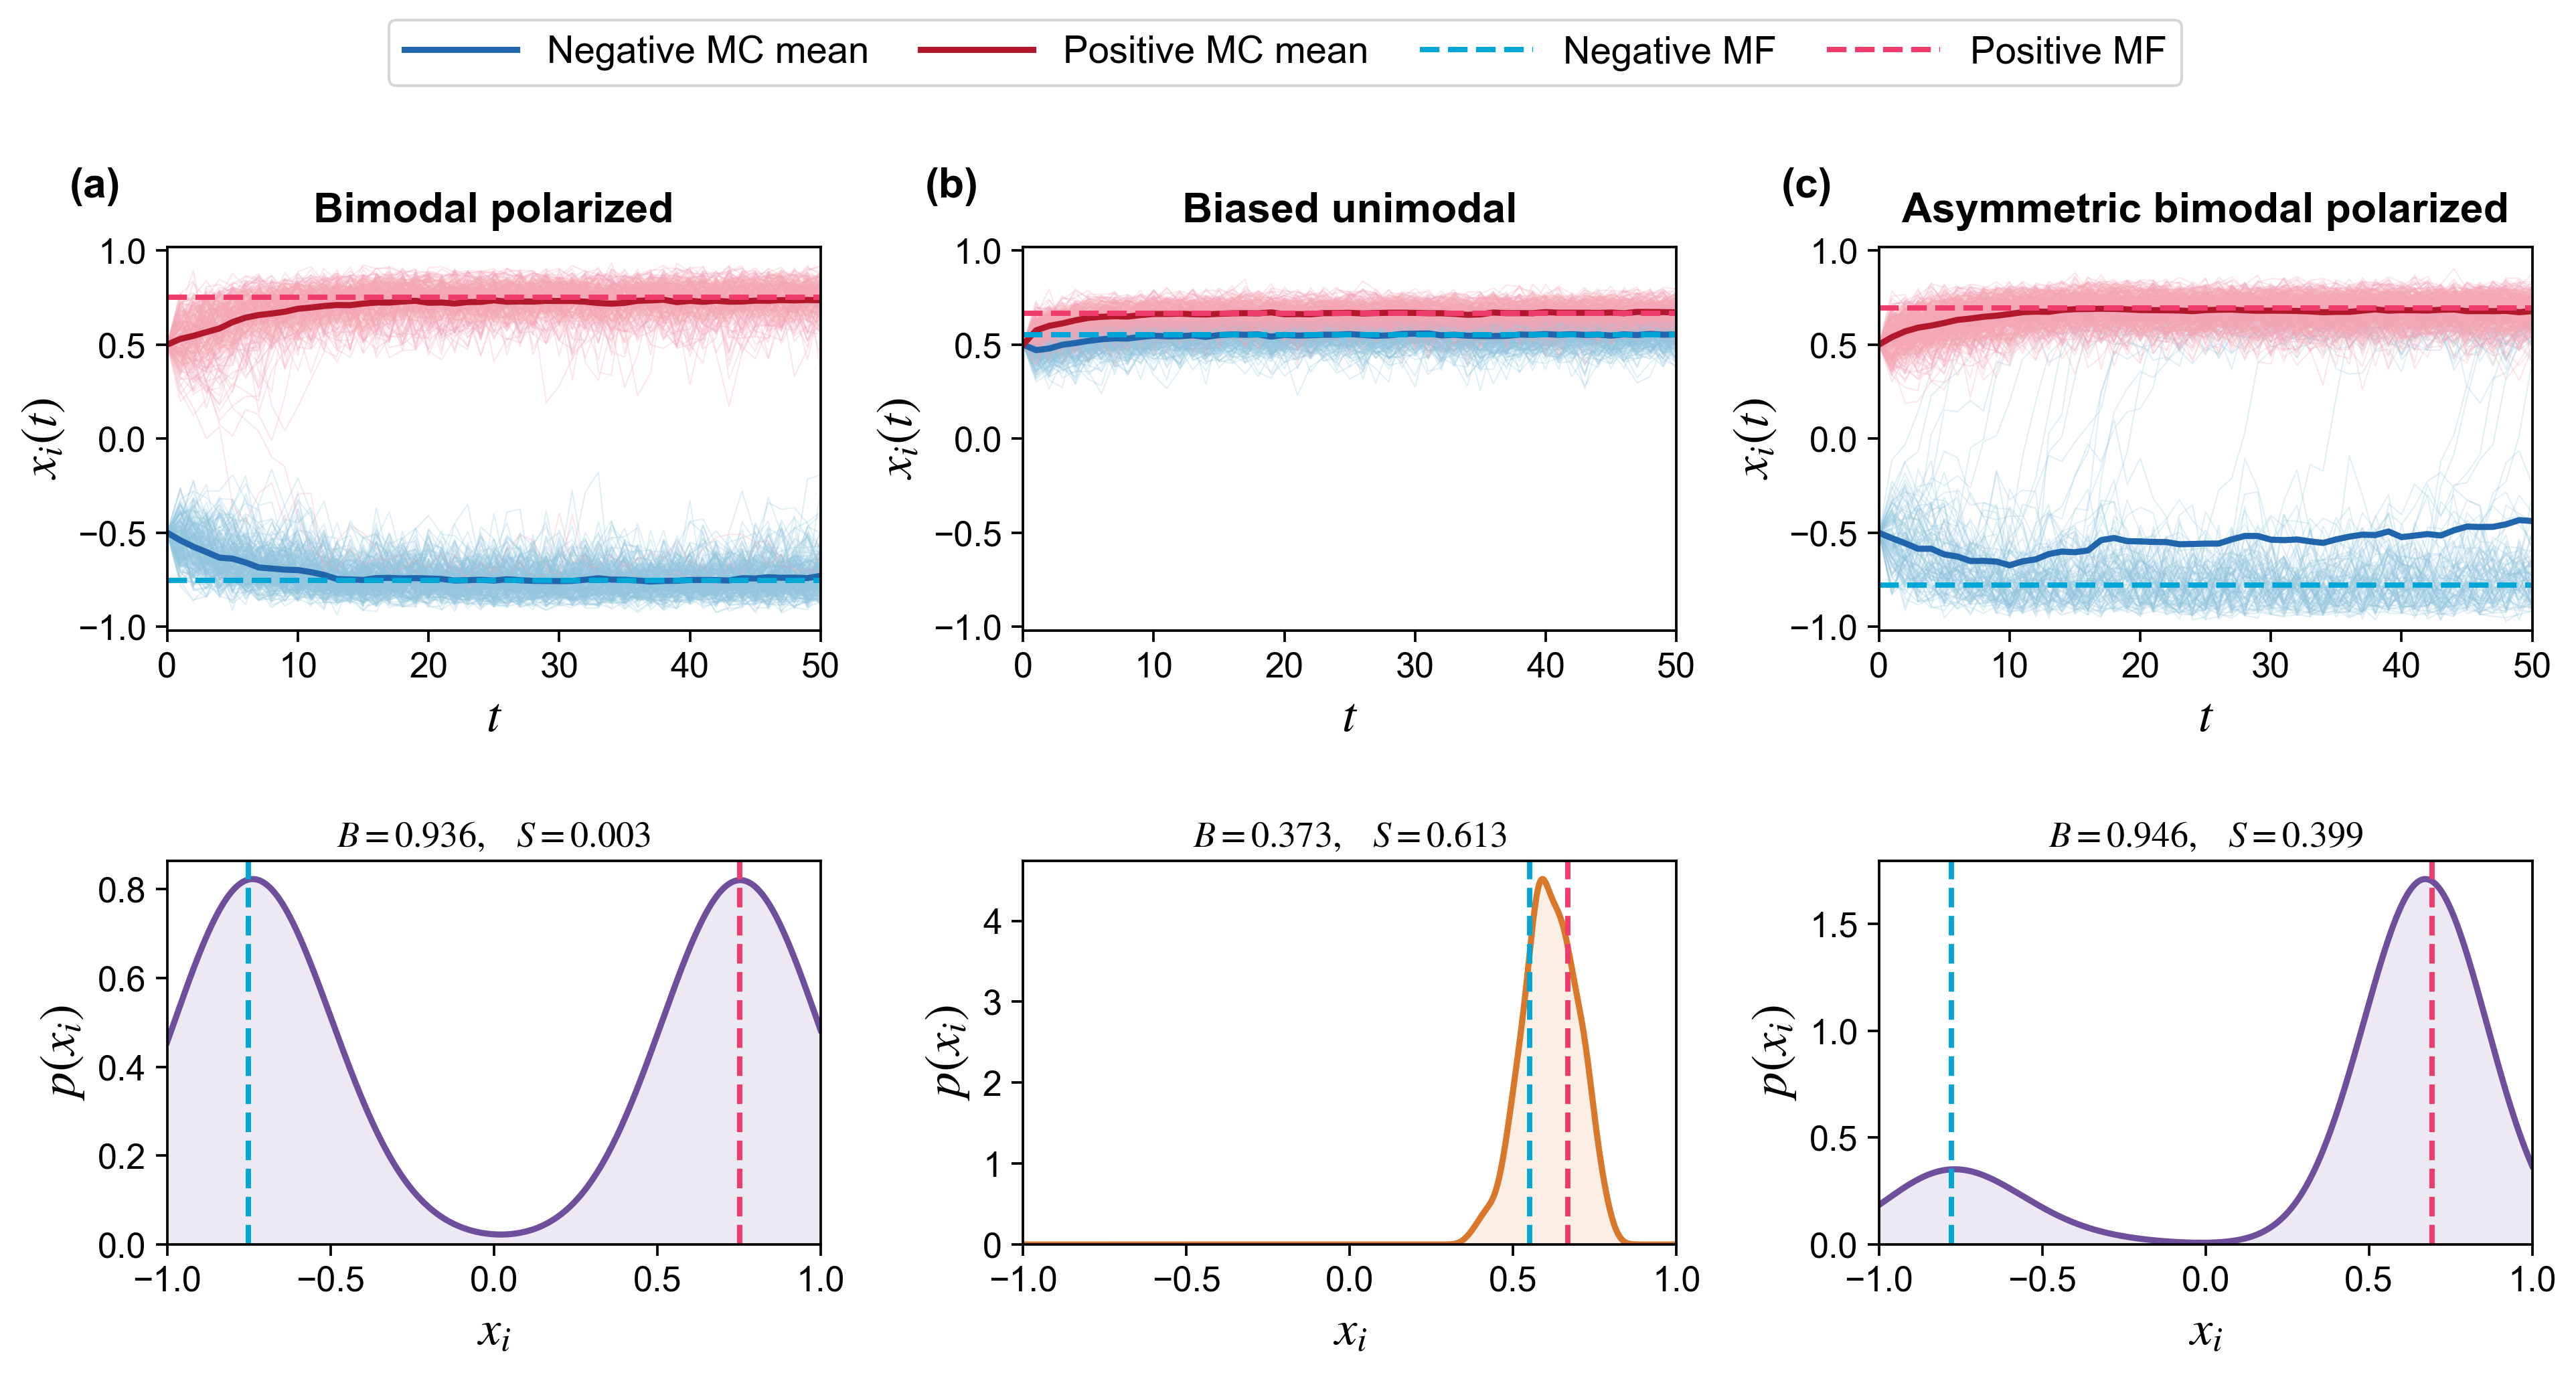

In [7]:
fig, axes = plt.subplots(
    2, 3, figsize=(12.8, 7.2), dpi=300,
    gridspec_kw={'left': 0.065, 'right': 0.985, 'bottom': 0.09, 'top': 0.78, 'wspace': 0.31, 'hspace': 0.60},
)
for column, case in enumerate(cases):
    result = results[case['key']]
    draw_trajectory(axes[0, column], result, case)
    draw_distribution(axes[1, column], result, case)
    axes[0, column].set_title(case['name'], fontsize=15, fontweight='semibold', pad=9)
    axes[0, column].text(
        -0.15, 1.13, case['panel'], transform=axes[0, column].transAxes,
        fontsize=15, fontweight='bold',
    )
    axes[1, column].set_title(
        rf"$B={result['B']:.3f},\quad S={result['S']:.3f}$",
        fontsize=13, pad=5,
    )
fig.legend(
    handles=legend_handles, loc='upper center', ncol=4, frameon=True,
    bbox_to_anchor=(0.5, 0.95), fontsize=13.5, handlelength=3.0, columnspacing=1.35,
)
complete_base = figure_dir / 'three_states_K40_T50_seed62_complete_v2'
fig.savefig(str(complete_base) + '.svg', bbox_inches='tight')
fig.savefig(str(complete_base) + '.pdf', bbox_inches='tight')
fig.savefig(str(complete_base) + '.png', dpi=600, bbox_inches='tight')
plt.show()